In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
df = pd.read_csv('./datasets/students_dropout_academic_success.csv')

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

## Column Removal — Dataset Adaptation

Several columns from the original dataset were dropped, as they are specific to the Portuguese higher-education admission system and economic context, and do not translate meaningfully to a Brazilian institution. Including them would not add predictive value for our use case — they either don't apply to Brazilian students or remain constant across the cohort, providing no discriminative signal for the model.

**Dropped columns:**
- `Application mode`, `Application order`, `Previous qualification`, `Previous qualification (grade)` — tied to Portugal's specific admission process, with no equivalent in the Brazilian system.
- `Marital status`, `Nacionality`, `International`, `Displaced` — demographic attributes with no clear or documented relationship to the dropout risk categories defined for this project.
- `Mother's qualification`, `Father's qualification`, `Mother's occupation`, `Father's occupation` — family background data not collected in our student registration flow.
- `Unemployment rate`, `Inflation rate`, `GDP` — macroeconomic indicators tied to Portugal's national context at the time of data collection; irrelevant to individual student risk and constant across each cohort.
- `Curricular units 1st sem (credited)`, `Curricular units 2nd sem (credited)` — edge case representing credit recognition from prior studies, rare enough to be dropped without meaningful information loss.

In [12]:
df = df.drop(columns=[
    "Application mode",
    "Application order",
    "Previous qualification",
    "Previous qualification (grade)",
    "Marital status",
    "Nacionality",
    "International",
    "Displaced",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
    "Curricular units 1st sem (credited)",
    "Curricular units 2nd sem (credited)",
], errors="ignore")

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 21 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Course                                          4424 non-null   int64  
 2   Daytime/evening attendance                      4424 non-null   int64  
 3   Admission grade                                 4424 non-null   float64
 4   Educational special needs                       4424 non-null   int64  
 5   Debtor                                          4424 non-null   int64  
 6   Tuition fees up to date                         4424 non-null   int64  
 7   Gender                                          4424 non-null   int64  
 8   Scholarship holder                              4424 non-null   int64  
 9   Age at enrollment                               4424

In [14]:
df.head(10)

,Marital Status,Course,Daytime/evening attendance,Admission grade,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,...,Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),target
0,1,171,1,127.3,0,0,1,1,0,20,...,0,0,0.000000,0,0,0,0,0.000000,0,Dropout
1,1,9254,1,142.5,0,0,0,1,0,19,...,6,6,14.000000,0,6,6,6,13.666667,0,Graduate
2,1,9070,1,124.8,0,0,0,1,0,19,...,0,0,0.000000,0,6,0,0,0.000000,0,Dropout
3,1,9773,1,119.6,0,0,1,0,0,20,...,8,6,13.428571,0,6,10,5,12.400000,0,Graduate
4,2,8014,0,141.5,0,0,1,0,0,45,...,9,5,12.333333,0,6,6,6,13.000000,0,Graduate
5,2,9991,0,114.8,0,1,1,1,0,50,...,10,5,11.857143,0,5,17,5,11.500000,5,Graduate
6,1,9500,1,128.4,0,0,1,0,1,18,...,9,7,13.300000,0,8,8,8,14.345000,0,Graduate
7,1,9254,1,113.1,0,0,0,1,0,22,...,5,0,0.000000,0,5,5,0,0.000000,0,Dropout
8,1,9238,1,129.3,0,0,1,0,1,21,...,8,6,13.875000,0,6,7,6,14.142857,0,Graduate
9,1,9238,1,123.0,0,1,0,0,0,18,...,9,5,11.400000,0,6,14,2,13.500000,0,Dropout


In [15]:
df.dtypes

Marital Status                                      int64
Course                                              int64
Daytime/evening attendance                          int64
Admission grade                                   float64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender                                              int64
Scholarship holder                                  int64
Age at enrollment                                   int64
Curricular units 1st sem (enrolled)                 int64
Curricular units 1st sem (evaluations)              int64
Curricular units 1st sem (approved)                 int64
Curricular units 1st sem (grade)                  float64
Curricular units 1st sem (without evaluations)      int64
Curricular units 2nd sem (enrolled)                 int64
Curricular units 2nd sem (evaluations)              int64
Curricular uni

## EDA

<Axes: xlabel='target', ylabel='count'>

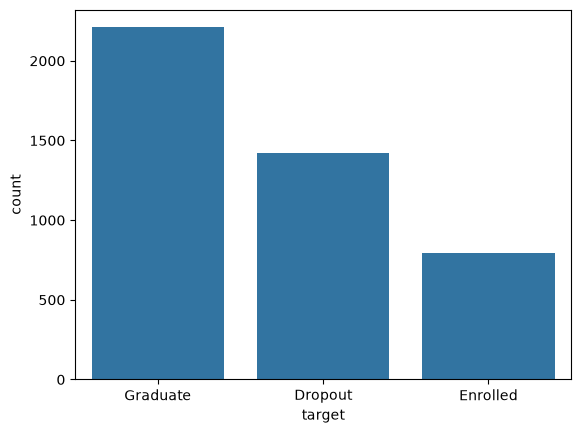

In [16]:
sns.barplot(df['target'].value_counts())

In [17]:
# Moderate class imbalance: Graduate (~50%) is roughly the majority class, while
# Dropout (~32%) and Enrolled (~18%) are underrepresented. Not extreme enough to
# require aggressive resampling (e.g. SMOTE), but worth using stratify + class_weight
# later to keep the model from favoring the majority class.

In [21]:
import numpy as np

# Binary target: 1 = at risk (Dropout), 0 = not at risk (Graduate or currently Enrolled)
df["risk"] = np.where(df["target"] == "Dropout", 1, 0)

# Sanity check: confirm the binary distribution
df["risk"].value_counts()

risk
0    3003
1    1421
Name: count, dtype: int64

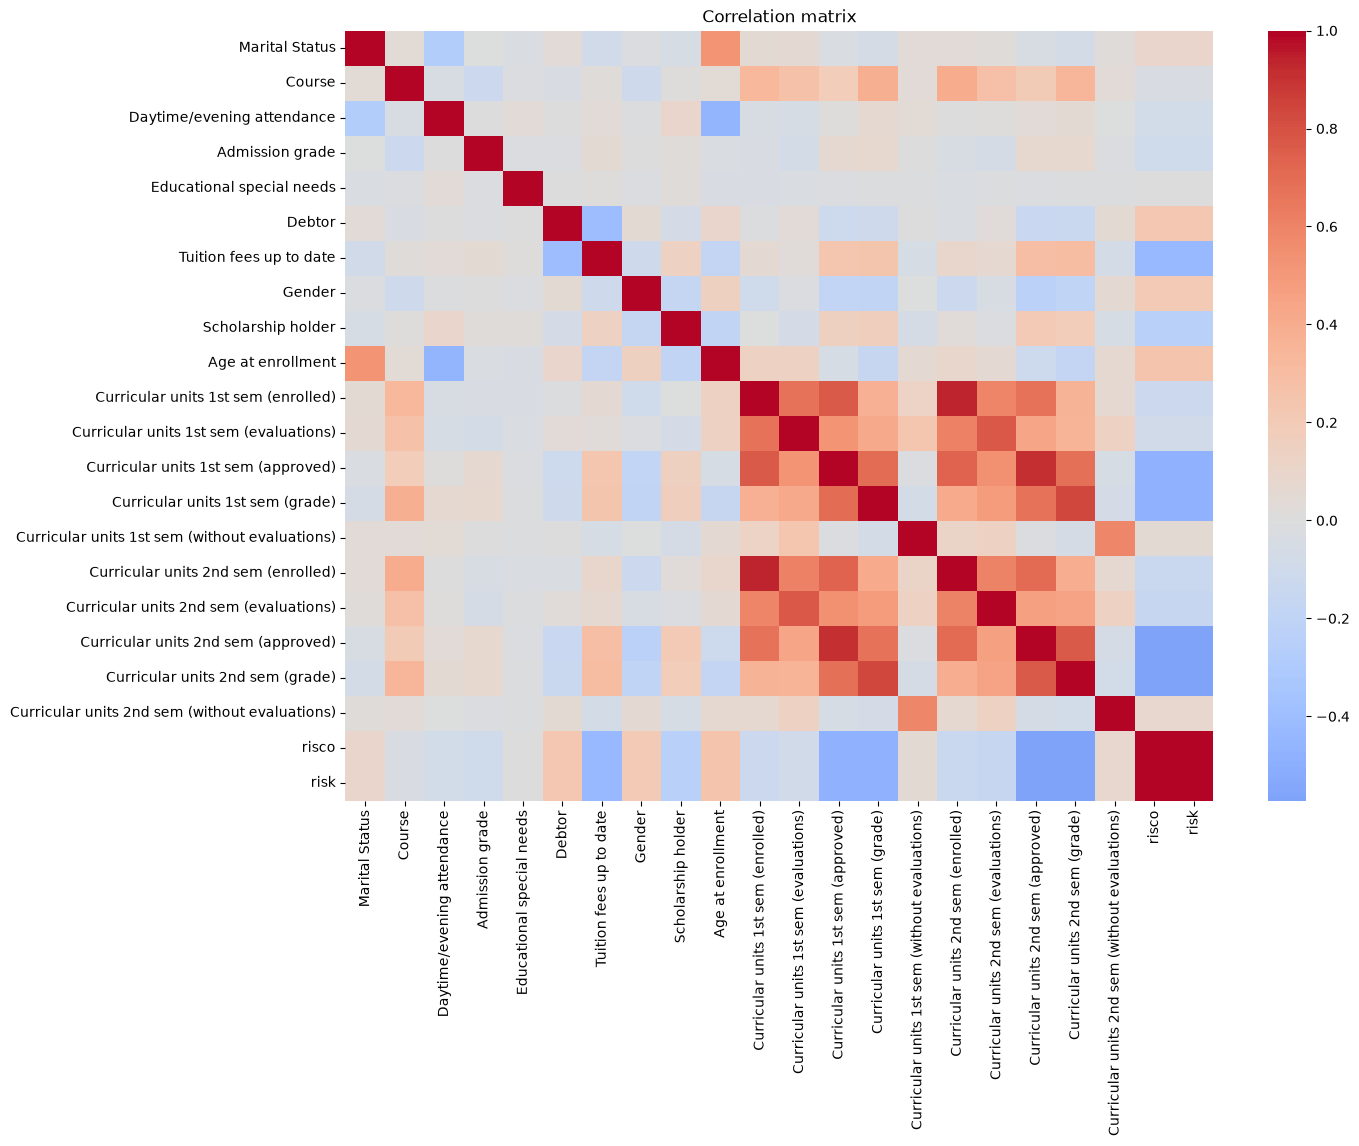

risco                                             1.000000
risk                                              1.000000
Age at enrollment                                 0.254215
Debtor                                            0.229407
Gender                                            0.203983
Marital Status                                    0.093712
Curricular units 2nd sem (without evaluations)    0.079901
Curricular units 1st sem (without evaluations)    0.054230
Educational special needs                         0.002806
Course                                           -0.033676
Daytime/evening attendance                       -0.080499
Curricular units 1st sem (evaluations)           -0.090125
Admission grade                                  -0.095806
Curricular units 1st sem (enrolled)              -0.124635
Curricular units 2nd sem (enrolled)              -0.141515
Curricular units 2nd sem (evaluations)           -0.154999
Scholarship holder                               -0.2453

In [22]:
# Correlation matrix between numeric features and the binary target — helps validate
# whether the variables chosen for each root-cause category actually relate to risk
corr = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix")
plt.show()

# Correlation of each feature specifically with the target, sorted —
# quick way to see which variables matter most before training
corr["risk"].sort_values(ascending=False)

In [23]:
df = df.drop(columns=["risco"])

In [24]:
# Re-confirm columns dropped earlier still not present in this session's dataframe
# (Marital Status showed up again in the correlation output, so this re-applies
# the same drop list as a safety net)
drop_columns = [
    "Application mode", "Application order", "Previous qualification",
    "Previous qualification (grade)", "Marital Status", "Nacionality",
    "International", "Displaced", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", "Unemployment rate",
    "Inflation rate", "GDP", "Curricular units 1st sem (credited)",
    "Curricular units 2nd sem (credited)",
]
df = df.drop(columns=drop_columns, errors="ignore")

# Confirm final shape and remaining columns before moving to X/y split
print(df.shape)
print(df.columns.tolist())

(4424, 21)
['Course', 'Daytime/evening attendance', 'Admission grade', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'target', 'risk']


## Model Training - RandomForestClassifier

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [31]:

X = df.drop(columns=["target", "risk"])
y = df["risk"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
)

model_rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [32]:
y_pred = model_rf.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.91      0.89       569
           1       0.83      0.76      0.79       316

    accuracy                           0.86       885
   macro avg       0.85      0.84      0.84       885
weighted avg       0.86      0.86      0.86       885

[[519  50]
 [ 76 240]]


In [33]:
probs = model_rf.predict_proba(X_test)[:, 1]
y_pred_fitted = (probs >= 0.35).astype(int)

print(classification_report(y_test, y_pred_fitted))

              precision    recall  f1-score   support

           0       0.90      0.80      0.85       569
           1       0.71      0.84      0.77       316

    accuracy                           0.82       885
   macro avg       0.80      0.82      0.81       885
weighted avg       0.83      0.82      0.82       885



In [34]:
# Try a few thresholds to see how recall (class 1) trades off against precision
for t in [0.30, 0.35, 0.40, 0.45]:
    y_pred_t = (probs >= t).astype(int)
    report = classification_report(y_test, y_pred_t, output_dict=True)
    print(f"threshold={t} | recall(1)={report['1']['recall']:.2f} | precision(1)={report['1']['precision']:.2f}")

threshold=0.3 | recall(1)=0.87 | precision(1)=0.67
threshold=0.35 | recall(1)=0.84 | precision(1)=0.71
threshold=0.4 | recall(1)=0.82 | precision(1)=0.75
threshold=0.45 | recall(1)=0.79 | precision(1)=0.80


In [37]:
THRESHOLD_RISK = 0.35

y_pred_final = (probs >= THRESHOLD_RISK).astype(int)

# Feature importances tell us which variables the model relies on most to
# distinguish at-risk students — this is what will map to your 3 root-cause
# categories (Desempenho Acadêmico, Financeiro, Perfil de Entrada) in the dashboard
importances = pd.DataFrame({
    "feature": X.columns,
    "importance": model_rf.feature_importances_
}).sort_values("importance", ascending=False)

print(importances.head(15))

                                   feature  importance
16     Curricular units 2nd sem (approved)    0.177978
17        Curricular units 2nd sem (grade)    0.163684
11     Curricular units 1st sem (approved)    0.106914
12        Curricular units 1st sem (grade)    0.085758
2                          Admission grade    0.084941
8                        Age at enrollment    0.065752
5                  Tuition fees up to date    0.065724
15  Curricular units 2nd sem (evaluations)    0.049791
0                                   Course    0.045900
10  Curricular units 1st sem (evaluations)    0.037922
9      Curricular units 1st sem (enrolled)    0.023426
14     Curricular units 2nd sem (enrolled)    0.022034
4                                   Debtor    0.018707
7                       Scholarship holder    0.018596
6                                   Gender    0.013681


In [38]:
# Importance grouped by root-cause category (based on the model's top 15 features):
# - Desempenho Acadêmico (approved units, grades, evaluations, both semesters): ~67%
# - Perfil de Entrada (admission grade, age at enrollment): ~15%
# - Financeiro (tuition fees, debtor, scholarship): ~10%
# Desempenho Acadêmico dominates the model's decisions by a wide margin — this
# matches the correlation analysis done earlier and should be the headline
# finding in the documentation